Assessment 1: Machine-learning analysis of Argo profile data

*OCES 5303 - Machine Learning for Ocean Science*

**Student ID:** 21421489

**Data source:** Argo archive shared via Google Drive (https://drive.google.com/drive/folders/1JJ0cpshu6-JE8wp93UsHuqy6V33rQy7s?usp=sharing)


<a id="contents"></a>
## Contents

1. [Introduction and background](#s1)
2. [Data: loading, quality control and sampling](#s2)
3. [Exploring the data](#s3)
4. [Machine-learning experiment: predicting $N^2$](#s4)
5. [Robustness checks and a physics-informed extension](#s5)
6. [Limitations](#s6)
7. [Conclusion](#s7)
8. [References](#refs)
   

<a id="s1"></a>
# 1. Introduction and background

Argo is a global array of autonomous profiling floats that repeatedly dive from about 2000 m to the surface, measuring temperature and salinity as a function of pressure (Roemmich et al., 2009). The data, downloaded from the Argo archive shared via Google Drive, span 11 June 1999 to 6 January 2014-5,322 days or about 14.5 years and contain 128,910 profile records, including 126,048 unique timestamps. The file used here is a subset of Argo profiles on a regular vertical grid, with four variables per profile:

| Variable | Data name | Units | Physical meaning |
|---|---|---|---|
| Sea_water_temperature | `TEMP`| C | Sea Temperature In-Situ ITS-90 Scale |
| Sea_water_salinity | `PSAL`| psu | Practical Salinity |
| Sea_water_density | `SIG0`| kg/m^3 | Potential Density Referenced to Surface |
| N2 | `BRV2`| 1/s^2 | Brunt-Vaisala Frequency Squared |


Temperature and salinity together set density through the equation of state. The quantity I focus on is the **squared buoyancy (Brunt-Vaisala) frequency**,

\begin{equation*}
    N^2 \;=\; -\frac{g}{\rho_0}\frac{\partial \sigma_0}{\partial z}
    \;\approx\; \frac{g}{\rho_0}\frac{\partial \sigma_0}{\partial d}
    \;\approx\; g\left(\beta \frac{\partial S}{\partial d} - \alpha \frac{\partial T}{\partial d}\right),
\end{equation*}

where $d$ is depth (positive downward), $g$ is gravity, $\rho_0$ a reference density, and $\alpha$, $\beta$ are the thermal-expansion and haline-contraction coefficients (last step: linearised equation of state; the sign convention makes $N^2>0$ for stable stratification). $N^2$ measures how strongly the water column resists vertical displacement: it is large in the seasonal thermocline/pycnocline, small in the well-mixed surface layer and in the deep ocean, and it controls vertical mixing and hence the exchange of heat, carbon and nutrients between the surface and the interior (Goh & Noh, 2013; Yamaguchi et al., 2019).

## Why a machine-learning problem?

$N^2$ is a *vertical gradient*, so it needs neighbouring levels of a profile. A regression model that only sees the state **at one level** ($T$, $S$, depth, position, time of year) has no direct access to that gradient; it can only learn the typical stratification associated with that state, like a climatological look-up table. That makes the following questions interesting rather than trivial:

* **Q1.** How well can $N^2$ be predicted on completely unseen profiles, and do flexible non-linear models (random forest, gradient boosting) beat regularised linear models?
* **Q2.** Which predictors carry the information?
* **Q3.** Where in the water column do the models fail?
* **Q4.** How much does the answer depend on *how* the data are split into training and test sets (random profiles versus a later time block)?
* **Q5** (extension). If the vertical gradients $\partial T/\partial d$ and $\partial S/\partial d$ *are* supplied, does the problem become essentially solved, as the equation above suggests?

## Models and metrics

Six regression models of increasing flexibility are compared, each mapping a feature vector $\mathbf{x}$ to $\hat y = \widehat{N^2}$:

1. **Linear regression (OLS):** $\hat y = a_0 + \sum_j a_j x_j$, minimising $J(\mathbf a)=\frac1N\sum_i(\hat y_i-y_i)^2$.
2. **Ridge ($L^2$)** : $J(\mathbf a)=\frac1N\sum_i(\hat y_i-y_i)^2+\alpha\sum_j a_j^2$.
3. **Lasso ($L^1$)** : $J(\mathbf a)=\frac1N\sum_i(\hat y_i-y_i)^2+\alpha\sum_j |a_j|$.
4. **Elastic net** : $J(\mathbf a)=\frac1N\sum_i(\hat y_i-y_i)^2+\alpha\big(\rho\sum_j|a_j|+\tfrac{1-\rho}{2}\sum_j a_j^2\big)$.
5. **Random forest** : $\hat y(\mathbf x)=\frac1B\sum_{b=1}^{B}T_b(\mathbf x)$, an average of $B$ decorrelated regression trees.
6. **Gradient boosting** : $F_b(\mathbf x)=F_{b-1}(\mathbf x)+\eta\,h_b(\mathbf x)$, trees added sequentially to fit the residuals (histogram-based implementation in scikit-learn; Pedregosa et al., 2011).

Skill is measured with

\begin{equation*}
\mathrm{R}^2 = 1-\frac{\sum_i(\hat y_i-y_i)^2}{\sum_i(y_i-\bar y)^2},\qquad
\mathrm{MAE}=\frac1N\sum_i|\hat y_i-y_i|,\qquad
\end{equation*}


## Set-up

The next cell loads the packages and collects every setting I might want to change in one place. All random choices are seeded.

In [3]:
import os, time, sys, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

# ------------------------------------------------------------------ settings
ZARR_PATH = "/Users/beekenshrestha/Downloads/UST_Doc/Courses/1st_Sem/OCES5303/GLOB_HOMOGENEOUS_variables.zarr/"

N_PROF_SAMPLE = 2500      # number of randomly chosen profiles used for modelling
N_CV_REPEATS  = 8         # repeated grouped train/validation splits for the CV box plots
TEST_FRACTION = 0.25      # fraction of profiles held out as the final test set
RNG_SEED      = 20240517

# vertical levels kept for modelling (m): fine near the surface, coarser at depth
DEPTH_GRID = np.r_[0., np.arange(10, 201, 10.), np.arange(225, 1001, 25.), np.arange(1050, 1501, 50.)]

# nominal expansion/contraction coefficients, only used for the physics check in section 5
GRAV, ALPHA_T, BETA_S = 9.81, 1.7e-4, 7.6e-4

# ------------------------------------------------------------------ plotting defaults
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": ":",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
np.random.seed(RNG_SEED)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"xarray {xr.__version__} | scikit-learn {sklearn.__version__}")

Python 3.12.2 | numpy 1.26.4 | pandas 2.2.3 | xarray 2024.11.0 | scikit-learn 1.5.2


A few small helper functions follow, kept together so the analysis cells stay short: a figure saver, the metric bundle, a season labeller, and a mixed-layer-depth estimator. For the latter I use the standard density-threshold definition, the depth at which $\sigma_0$ first exceeds its 10 m value by $0.03\ \mathrm{kg\,m^{-3}}$.

In [6]:
os.makedirs("figures", exist_ok=True)

def save(fig, name):
    """save a figure to ./figures as a 200 dpi PNG"""
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

def evaluate(y_true, y_pred):
    """R2, MAE and RMSE in one dictionary"""
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred)))}

def season_of(month, southern=False):
    """meteorological season from month number (flipped for the southern hemisphere)"""
    north = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
             6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
    flip = {"Winter": "Summer", "Summer": "Winter", "Spring": "Autumn", "Autumn": "Spring"}
    s = pd.Series(np.asarray(month)).map(north)
    return (s.map(flip) if southern else s).to_numpy()

def mixed_layer_depth(sig0, depth, ref_depth=10.0, thresh=0.03):
    """
    density-threshold mixed layer depth for an array sig0[n_prof, n_depth]
    (first depth below ref_depth where sigma0 exceeds its ref_depth value by thresh)
    profiles that never exceed the threshold, or lack the reference value, return NaN
    """
    iref = np.abs(depth - ref_depth).argmin()
    ref = sig0[:, iref]
    exceed = (sig0 - ref[:, None]) > thresh
    exceed[:, depth < ref_depth] = False
    has = exceed.any(axis=1)
    mld = np.where(has, depth[exceed.argmax(axis=1)], np.nan)
    mld[~np.isfinite(ref)] = np.nan
    return mld

---
<a id="s2"></a>
# 2. Data: loading, quality control and sampling

## a) Opening the Zarr store

The Zarr store is opened lazily with `xarray` (nothing is read into memory yet). It has two dimensions, `N_PROF` (one entry per profile) and `DEPTH` (a regular vertical grid), with `TIME`, `LATITUDE` and `LONGITUDE` stored per profile.

In [9]:
if not os.path.exists(ZARR_PATH):
    raise FileNotFoundError(
        f"Zarr store not found at {ZARR_PATH!r}. Download it from the Google Drive link at the top "
        "of the notebook and set ZARR_PATH above. (No synthetic fallback is used on purpose.)")

ds = xr.open_zarr(ZARR_PATH)
ds

<xarray.Dataset> Size: 626MB
Dimensions:    (N_PROF: 128910, DEPTH: 302)
Coordinates:
  * DEPTH      (DEPTH) float32 1kB 0.0 -5.0 -10.0 ... -1.5e+03 -1.505e+03
    TIME       (N_PROF) datetime64[ns] 1MB dask.array<chunksize=(64455,), meta=np.ndarray>
    LATITUDE   (N_PROF) float32 516kB dask.array<chunksize=(67010,), meta=np.ndarray>
    LONGITUDE  (N_PROF) float32 516kB dask.array<chunksize=(67010,), meta=np.ndarray>
Dimensions without coordinates: N_PROF
Data variables:
    TEMP       (N_PROF, DEPTH) float32 156MB dask.array<chunksize=(67010, 302), meta=np.ndarray>
    DBINDEX    (N_PROF) float64 1MB dask.array<chunksize=(67010,), meta=np.ndarray>
    PSAL       (N_PROF, DEPTH) float32 156MB dask.array<chunksize=(67010, 302), meta=np.ndarray>
    BRV2       (N_PROF, DEPTH) float32 156MB dask.array<chunksize=(67010, 302), meta=np.ndarray>
    SIG0       (N_PROF, DEPTH) float32 156MB dask.array<chunksize=(67010, 302), meta=np.ndarray>
Attributes:
    Title:             VENTHSAL-IA
    conventions:       CF-1.6
    conventions_help:  http://cf-pcmdi.llnl.gov/documents/cf-conventions/1.6/...
    createdBy:         gmaze
    createdWith:       /home8/homedir3/perso/gmaze/work/Projects/GMM/Argo-pro...
    creationDate:      2019/01/22 22:07:00
    dataset_file:      /home8/homedir3/perso/gmaze/data/ARGO/copoda_db/setup_...
    institution:       LPO/Ifremer
    long_title:        Argo subset of plain profiles for VENTHSAL-IA
    source:            VENTHSAL-Argo
    subset_ID:         1-2
    subset_maxnumber:  3.0

The per-profile coordinates are small (a few hundred kB), so I read those fully into memory. This gives the **complete** temporal and spatial coverage of the archive, independent of the random subsample used for modelling later. Note the `DEPTH` coordinate is stored as negative numbers (0, −5, −10, …), so I convert it to positive metres below the surface.

In [11]:
time_all  = pd.to_datetime(ds["TIME"].values)
lat_all   = ds["LATITUDE"].values.astype(float)
lon_all   = ds["LONGITUDE"].values.astype(float)
depth_all = np.abs(ds["DEPTH"].values.astype(float))          # metres, positive downward
n_prof_all = ds.sizes["N_PROF"]

assert np.all(np.diff(depth_all) > 0), "expected depth levels to increase monotonically"

print(f"Profiles        : {n_prof_all:,}  ({pd.Series(time_all).nunique():,} unique time stamps)")
print(f"First / last    : {time_all.min()}  →  {time_all.max()}")
print(f"Span            : {(time_all.max() - time_all.min()).days:,} days "
      f"({(time_all.max() - time_all.min()).days / 365.25:.1f} years)")
print(f"Latitude range  : {np.nanmin(lat_all):.2f} to {np.nanmax(lat_all):.2f} °N")
print(f"Longitude range : {np.nanmin(lon_all):.2f} to {np.nanmax(lon_all):.2f} °E")
print(f"Depth levels    : {depth_all.size} from {depth_all.min():.0f} to {depth_all.max():.0f} m "
      f"(spacing {np.median(np.diff(depth_all)):.0f} m)")
print("Dataset metadata:", {k: ds.attrs[k] for k in ("Title", "long_title", "institution") if k in ds.attrs})

Profiles        : 128,910  (126,048 unique time stamps)
First / last    : 1999-06-11 18:16:52.500000  →  2014-01-06 17:55:46.875000064
Span            : 5,322 days (14.6 years)
Latitude range  : -65.00 to 65.00 °N
Longitude range : -180.00 to 180.00 °E
Depth levels    : 302 from 0 to 1505 m (spacing 5 m)
Dataset metadata: {'Title': 'VENTHSAL-IA', 'long_title': 'Argo subset of plain profiles for VENTHSAL-IA', 'institution': 'LPO/Ifremer'}


## b) Random sampling of profiles and quality control

The full array is $128{,}910 \times 302$ values per variable, and stacking it into one long table would give tens of millions of rows, far too many for repeated random-forest fits. I therefore draw a **random sample of `N_PROF_SAMPLE` whole profiles** (whole profiles, not random points, so that the vertical structure of each profile stays intact). All 302 levels of the sampled profiles are read, because the vertical gradients used in §5 are best computed on the fine native grid; the modelling table later keeps a thinned set of levels (`DEPTH_GRID`).

Quality control is deliberately light, since the file is already a processed product: values outside generous physical limits are set to missing (and counted), and rows with missing values in the variables I use are dropped later. $N^2$ is very small in SI units ($\sim10^{-5}$–$10^{-3}\ \mathrm{s^{-2}}$), so I rescale it to units of $10^{-4}\ \mathrm{s^{-2}}$ (automatically, if the stored values are in SI units) to keep regression coefficients and error metrics readable.

In [13]:
rng = np.random.default_rng(RNG_SEED)
ok = np.flatnonzero(pd.notna(time_all) & np.isfinite(lat_all) & np.isfinite(lon_all))
idx = np.sort(rng.choice(ok, size=min(N_PROF_SAMPLE, ok.size), replace=False))   # original profile numbers

def load(var):
    """read the sampled profiles of one variable as a float array [n_prof, n_depth]"""
    return ds[var].isel(N_PROF=idx).transpose("N_PROF", "DEPTH").values.astype(float)

T, S, SIG, N2 = (load(v) for v in ["TEMP", "PSAL", "SIG0", "BRV2"])

# --- range checks (physically generous limits) -------------------------------------------
flags = {"TEMP": (T < -3) | (T > 40), "PSAL": (S < 0) | (S > 45),
         "SIG0": (SIG < 10) | (SIG > 35), "BRV2": np.abs(N2) > 0.1}
for name, arr, bad in [("TEMP", T, flags["TEMP"]), ("PSAL", S, flags["PSAL"]),
                       ("SIG0", SIG, flags["SIG0"]), ("BRV2", N2, flags["BRV2"])]:
    print(f"{name}: {int(bad.sum()):,} values outside range check set to NaN")
    arr[bad] = np.nan

# --- units of N^2 ------------------------------------------------------------------------
BRV2_SCALE = 1e4 if np.nanmedian(np.abs(N2)) < 1e-2 else 1.0
N2 = N2 * BRV2_SCALE
N2_LABEL = r"$N^2$ ($10^{-4}\,\mathrm{s^{-2}}$)" if BRV2_SCALE != 1 else r"$N^2$"
print(f"\nBRV2 scale factor applied: {BRV2_SCALE:g}  →  quantiles (1, 50, 99 %): "
      f"{np.round(np.nanpercentile(N2, [1, 50, 99]), 4)}")

# --- per-profile metadata ----------------------------------------------------------------
prof = pd.DataFrame({"PROF": idx, "TIME": time_all[idx], "LATITUDE": lat_all[idx], "LONGITUDE": lon_all[idx]})
prof["MONTH"] = prof.TIME.dt.month
SOUTHERN = bool(np.nanmedian(lat_all[ok]) < 0)
prof["SEASON"] = season_of(prof.MONTH, southern=SOUTHERN)

print(f"\nSampled {len(prof):,} of {n_prof_all:,} profiles "
      f"({100 * len(prof) / n_prof_all:.1f} %); seasons follow the {'southern' if SOUTHERN else 'northern'}-hemisphere convention.")
print("Missing fraction per variable (all sampled levels):",
      {k: round(float(np.isnan(a).mean()), 3) for k, a in dict(TEMP=T, PSAL=S, SIG0=SIG, BRV2=N2).items()})

TEMP: 0 values outside range check set to NaN
PSAL: 0 values outside range check set to NaN
SIG0: 0 values outside range check set to NaN
BRV2: 0 values outside range check set to NaN

BRV2 scale factor applied: 10000  →  quantiles (1, 50, 99 %): [2.0000e-04 6.8100e-02 2.6555e+00]

Sampled 2,500 of 128,910 profiles (1.9 %); seasons follow the southern-hemisphere convention.
Missing fraction per variable (all sampled levels): {'TEMP': 0.0, 'PSAL': 0.0, 'SIG0': 0.0, 'BRV2': 0.0}


## c) The modelling table

Next I build the **long-format table** used for machine learning, with one row per (profile, depth level). The predictors are

* `DEPTH`, `TEMP`, `PSAL`: the local state of the water,
* `LATITUDE`, `LONGITUDE`: position,
* `SIN_DOY`, `COS_DOY`: day of year encoded as a point on a circle, so that 31 December and 1 January are neighbours (a raw day number would put them at opposite ends of the scale),

and the target is `BRV2` ($N^2$). `SIG0` is **not** used as a predictor: it is an almost deterministic function of `TEMP`, `PSAL` and pressure, and $N^2$ is derived from its vertical gradient, so including it would blur what the model is learning (it is however explored in section 3).

Two further columns, `DTDZ` and `DSDZ`, are the vertical gradients of temperature and salinity computed on the full-resolution grid. They are **not** part of the baseline predictor set; they are reserved for the extension in section 5.

In [16]:
# vertical gradients on the native 5 m grid (per profile), then thin to the modelling levels
dTdz = np.gradient(T, depth_all, axis=1)
dSdz = np.gradient(S, depth_all, axis=1)

lvl = np.unique(np.abs(depth_all[:, None] - DEPTH_GRID[None, :]).argmin(axis=0))   # nearest native level to each target
n_p, n_l = len(idx), len(lvl)

df = pd.DataFrame({
    "PROF":      np.repeat(idx, n_l),
    "TIME":      np.repeat(prof.TIME.to_numpy(), n_l),
    "LATITUDE":  np.repeat(prof.LATITUDE.to_numpy(), n_l),
    "LONGITUDE": np.repeat(prof.LONGITUDE.to_numpy(), n_l),
    "SEASON":    np.repeat(prof.SEASON.to_numpy(), n_l),
    "DEPTH":     np.tile(depth_all[lvl], n_p),
    "TEMP":      T[:, lvl].ravel(),
    "PSAL":      S[:, lvl].ravel(),
    "SIG0":      SIG[:, lvl].ravel(),
    "DTDZ":      dTdz[:, lvl].ravel(),
    "DSDZ":      dSdz[:, lvl].ravel(),
    "BRV2":      N2[:, lvl].ravel(),
})
doy = pd.DatetimeIndex(df.TIME).dayofyear.to_numpy()
df["SIN_DOY"] = np.sin(2 * np.pi * doy / 365.25)
df["COS_DOY"] = np.cos(2 * np.pi * doy / 365.25)

n_before = len(df)
df = df.dropna(subset=["TEMP", "PSAL", "SIG0", "BRV2", "DTDZ", "DSDZ"]).reset_index(drop=True)
print(f"{n_p:,} profiles × {n_l} levels = {n_before:,} rows; {n_before - len(df):,} rows dropped for missing values "
      f"→ {len(df):,} rows from {df.PROF.nunique():,} profiles remain")
df.head()

2,500 profiles × 63 levels = 157,500 rows; 53 rows dropped for missing values → 157,447 rows from 2,500 profiles remain


,PROF,TIME,LATITUDE,LONGITUDE,SEASON,DEPTH,TEMP,PSAL,SIG0,DTDZ,DSDZ,BRV2,SIN_DOY,COS_DOY
0,0,2009-01-05 08:36:05.624999936,-62.167,-178.548996,Summer,0.0,3.076403,33.854000,26.963451,0.000000,0.000000,0.001812,0.085906,0.996303
1,0,2009-01-05 08:36:05.624999936,-62.167,-178.548996,Summer,10.0,3.076169,33.854000,26.963472,0.000060,0.000000,0.001812,0.085906,0.996303
2,0,2009-01-05 08:36:05.624999936,-62.167,-178.548996,Summer,20.0,3.077000,33.854000,26.963398,0.000000,0.000000,0.000525,0.085906,0.996303
3,0,2009-01-05 08:36:05.624999936,-62.167,-178.548996,Summer,30.0,3.077152,33.854000,26.963385,0.000100,-0.000012,-0.001427,0.085906,0.996303
4,0,2009-01-05 08:36:05.624999936,-62.167,-178.548996,Summer,40.0,3.076351,33.852966,26.962633,-0.001541,-0.000127,0.003074,0.085906,0.996303


---
<a id="s3"></a>
# 3. Exploring the data

Before modelling anything I want to know what the data look like: where and when the profiles were taken, how the variables relate to each other, and what the vertical structure looks like through the seasons.

## a) Where and when: spatial and temporal coverage

The left panel places every one of the 128,910 profiles on a map, coloured by year; the right panel shows the same positions as a density (log colour scale), which is more informative where the points overlap. Argo coverage is typically uneven in space and time (floats are deployed in batches and then drift with the currents), which matters for how I split the data into training and test sets later; the figure shows what it looks like in this file.

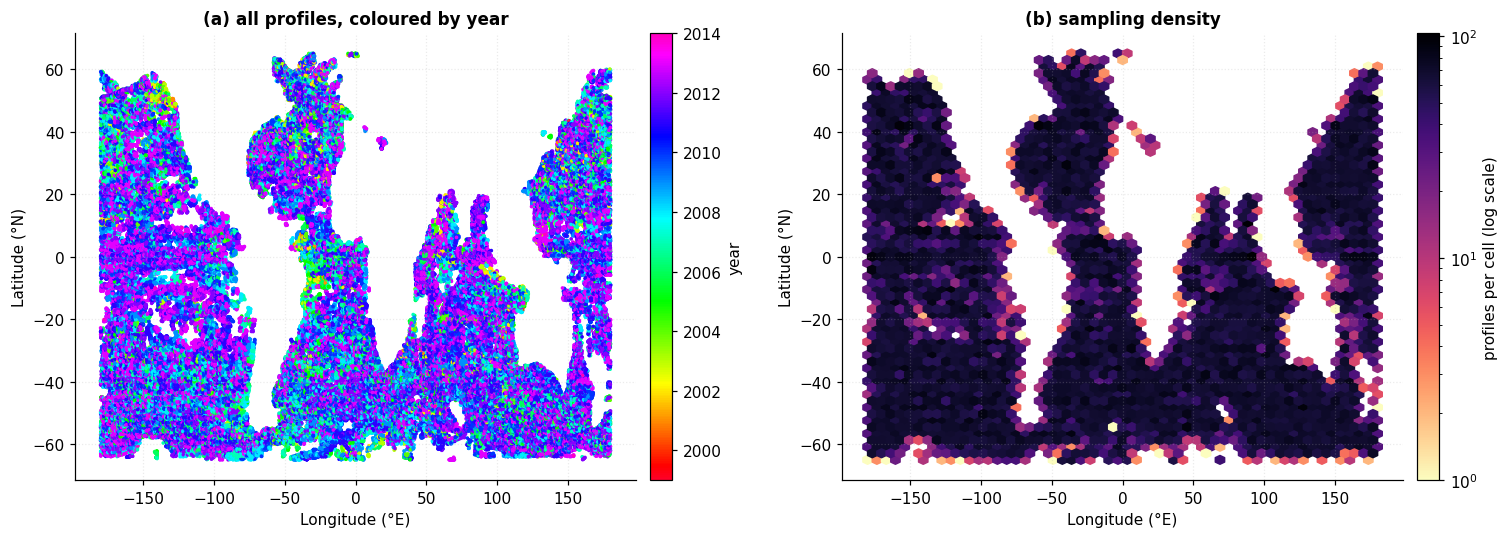

In [19]:
good = np.isfinite(lon_all) & np.isfinite(lat_all) & pd.notna(time_all)
years_all = time_all.year.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc = axes[0].scatter(lon_all[good], lat_all[good], c=years_all[good], s=2, cmap="gist_rainbow", rasterized=True)
fig.colorbar(sc, ax=axes[0], pad=0.02).set_label("year")
axes[0].set_title("(a) all profiles, coloured by year")

hb = axes[1].hexbin(lon_all[good], lat_all[good], gridsize=55, bins="log", mincnt=1, cmap="magma_r")
fig.colorbar(hb, ax=axes[1], pad=0.02).set_label("profiles per cell (log scale)")
axes[1].set_title("(b) sampling density")

for ax in axes:
    ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
plt.tight_layout(); save(fig, "fig1_map"); plt.show()

The next figure shows the number of profiles per calendar year and per month, i.e. whether the record is dominated by particular years or seasons.

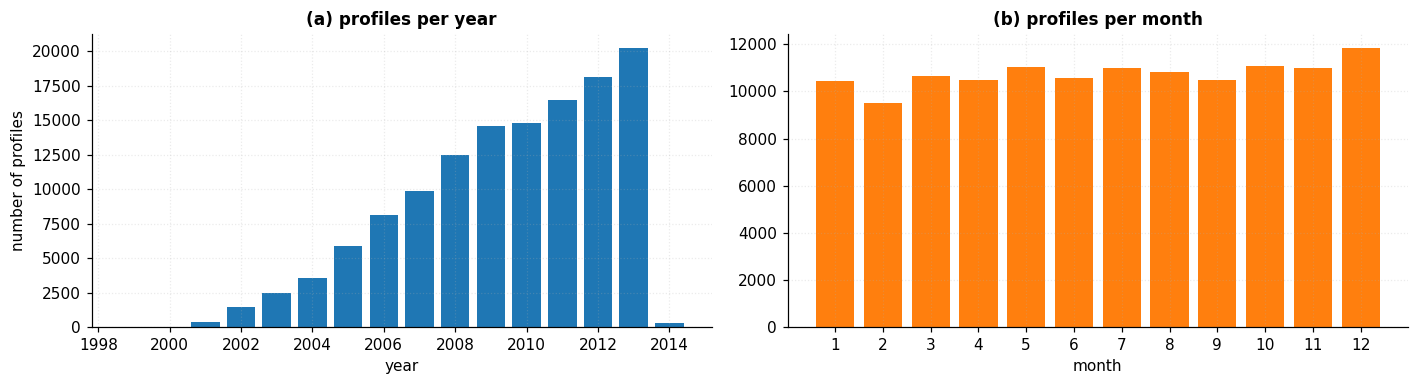

Profile counts range from 15 in 1999 to 20,226 in 2013, and the last five years hold 54 % of the record against 3 % for the first five. Within the calendar year the sampling is more even: month 12 has the most profiles and month 2 the fewest, a ratio of 1.25. Any change in sampling through time matters later, because a model trained on the early years is then asked to predict the late ones (section 5a).

In [21]:
per_year  = pd.Series(years_all[good]).value_counts().sort_index()
per_month = pd.Series(time_all.month.to_numpy()[good]).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].bar(per_year.index, per_year.values, color="C0"); axes[0].set_xlabel("year"); axes[0].set_ylabel("number of profiles")
axes[0].set_title("(a) profiles per year")
axes[1].bar(per_month.index, per_month.values, color="C1"); axes[1].set_xlabel("month"); axes[1].set_xticks(range(1, 13))
axes[1].set_title("(b) profiles per month")
plt.tight_layout(); save(fig, "fig2_coverage"); plt.show()

yr_max, yr_min = per_year.idxmax(), per_year.idxmin()
mo_max, mo_min = per_month.idxmax(), per_month.idxmin()
display(Markdown(
    f"Profile counts range from {per_year.min():,} in {yr_min} to {per_year.max():,} in {yr_max}, and the last five years hold {100 * per_year.iloc[-5:].sum() / per_year.sum():.0f} % of the record "
    f"against {100 * per_year.iloc[:5].sum() / per_year.sum():.0f} % for the first five. Within the calendar year the sampling is more even: month {mo_max} has the most profiles and month {mo_min} the fewest, "
    f"a ratio of {per_month.max() / per_month.min():.2f}. Any change in sampling through time matters later, because a model trained on the early years is then asked to predict the late ones (section 5a)."))

## b) Distributions, correlations and collinearity

Temperature, salinity and density all change with depth in a coordinated way, so the raw variables are likely to be strongly related to each other. This matters for the regression models: when predictors are highly correlated, the individual coefficients of ordinary least squares become unstable, which is the classic motivation for ridge, lasso and elastic-net penalties. The figure shows the histograms of the variables (with $N^2$ on a log axis, since it spans orders of magnitude) and the Pearson correlation matrix of the variables in the modelling table.

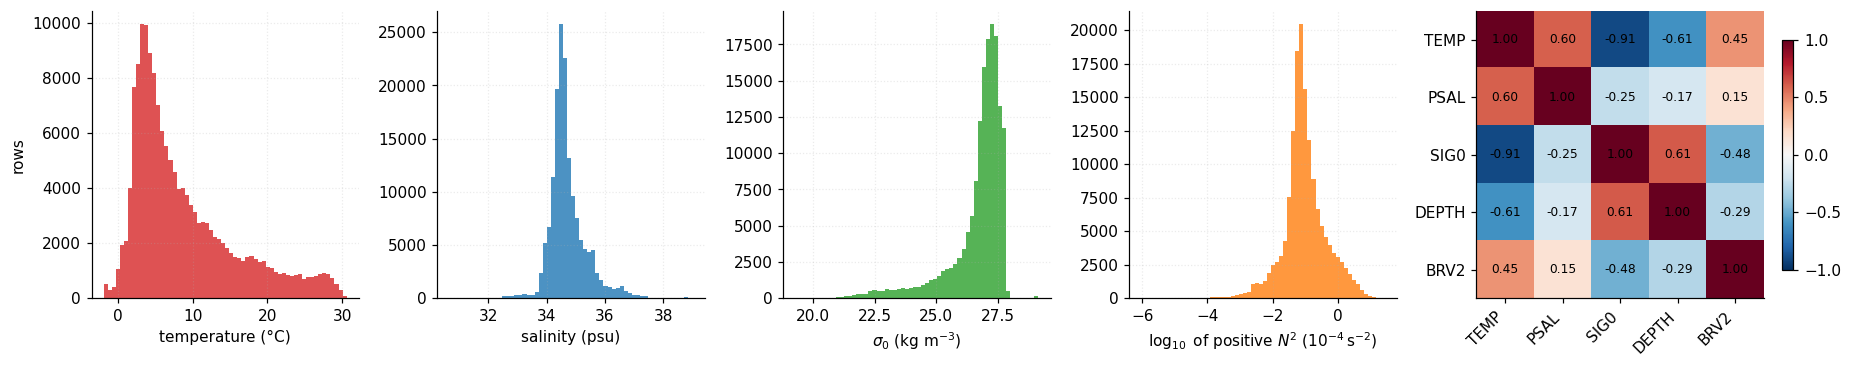

Variance inflation factors of the baseline predictors:
TEMP         2.84
DEPTH        1.82
PSAL         1.71
LATITUDE     1.12
LONGITUDE    1.01
SIN_DOY      1.00
COS_DOY      1.00


Temperature and $\sigma_0$ are strongly anti-correlated (r = -0.905), which is the equation of state at work: warmer water is lighter. Temperature and salinity are also related (r = 0.596). $N^2$ correlates most strongly with SIG0 (r = -0.48), so no single variable gives a linear description of the stratification. The largest variance inflation factor is 2.8 for TEMP. Values above about 5 to 10 are usually read as a sign of troublesome collinearity, so for these predictors it is a mild issue at most.

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.35]})
for ax, (v, lab, c) in zip(axes[:3], [("TEMP", "temperature (°C)", "C3"), ("PSAL", "salinity (psu)", "C0"), ("SIG0", "$\\sigma_0$ (kg m$^{-3}$)", "C2")]):
    ax.hist(df[v], bins=60, color=c, alpha=0.8); ax.set_xlabel(lab); ax.set_ylabel("rows" if v == "TEMP" else "")
pos = df.BRV2[df.BRV2 > 0]
axes[3].hist(np.log10(pos), bins=60, color="C1", alpha=0.8); axes[3].set_xlabel("$\\log_{10}$ of positive " + N2_LABEL)

corr_vars = ["TEMP", "PSAL", "SIG0", "DEPTH", "BRV2"]
corr = df[corr_vars].corr()
im = axes[4].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
axes[4].set_xticks(range(len(corr))); axes[4].set_xticklabels(corr.columns, rotation=45, ha="right")
axes[4].set_yticks(range(len(corr))); axes[4].set_yticklabels(corr.columns); axes[4].grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        axes[4].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=axes[4], shrink=0.8)
plt.tight_layout(); save(fig, "fig3_distributions_correlation"); plt.show()

# variance inflation factors for the baseline predictors: VIF_j = [C^{-1}]_jj with C the correlation matrix
FEATURES = ["DEPTH", "TEMP", "PSAL", "LATITUDE", "LONGITUDE", "SIN_DOY", "COS_DOY"]
C = np.corrcoef(df[FEATURES].to_numpy(float).T)
vif = pd.Series(np.diag(np.linalg.inv(C)), index=FEATURES).sort_values(ascending=False)
print("Variance inflation factors of the baseline predictors:"); print(vif.round(2).to_string())

r = corr["BRV2"].drop("BRV2")
display(Markdown(
    f"Temperature and $\\sigma_0$ are strongly anti-correlated (R² = {corr.loc['TEMP', 'SIG0']:.3f}), which is the equation of state at work: warmer water is lighter. Temperature and salinity are also related (r = {corr.loc['TEMP', 'PSAL']:.3f}). "
    f"$N^2$ correlates most strongly with {r.abs().idxmax()} (R² = {r[r.abs().idxmax()]:.2f}), so no single variable gives a linear description of the stratification. "
    f"The largest variance inflation factor is {vif.iloc[0]:.1f} for {vif.index[0]}. Values above about 5 to 10 are usually read as a sign of troublesome collinearity, so for these predictors it is "
    f"{'a real concern for the ordinary least squares coefficients' if vif.iloc[0] > 5 else 'a mild issue at most'}."))

## c) Vertical structure through the seasons

The next figure shows the vertical structure of temperature, salinity, potential density and $N^2$, for the four seasons. Thin lines are individual profiles (a random subset of 40 per season); the thick lines are the seasonal **mean** for $T$, $S$ and $\sigma_0$ and the seasonal **median** for $N^2$ (the median is more robust here, because individual $N^2$ profiles are noisy and can even be negative where the estimated stratification is unstable). Values of $N^2$ are on a log axis, so non-positive medians are not drawn.

What I expect from the physics is that the seasonal cycle is confined mostly to the upper few hundred metres: warm, strongly stratified surface waters over a shallow mixed layer in summer, versus cooler, deeper and more homogeneous mixing in winter (Goh & Noh, 2013; Yamaguchi et al., 2019), while the deep profiles of the different seasons should nearly coincide. The figure and the table below test whether that holds in this dataset.

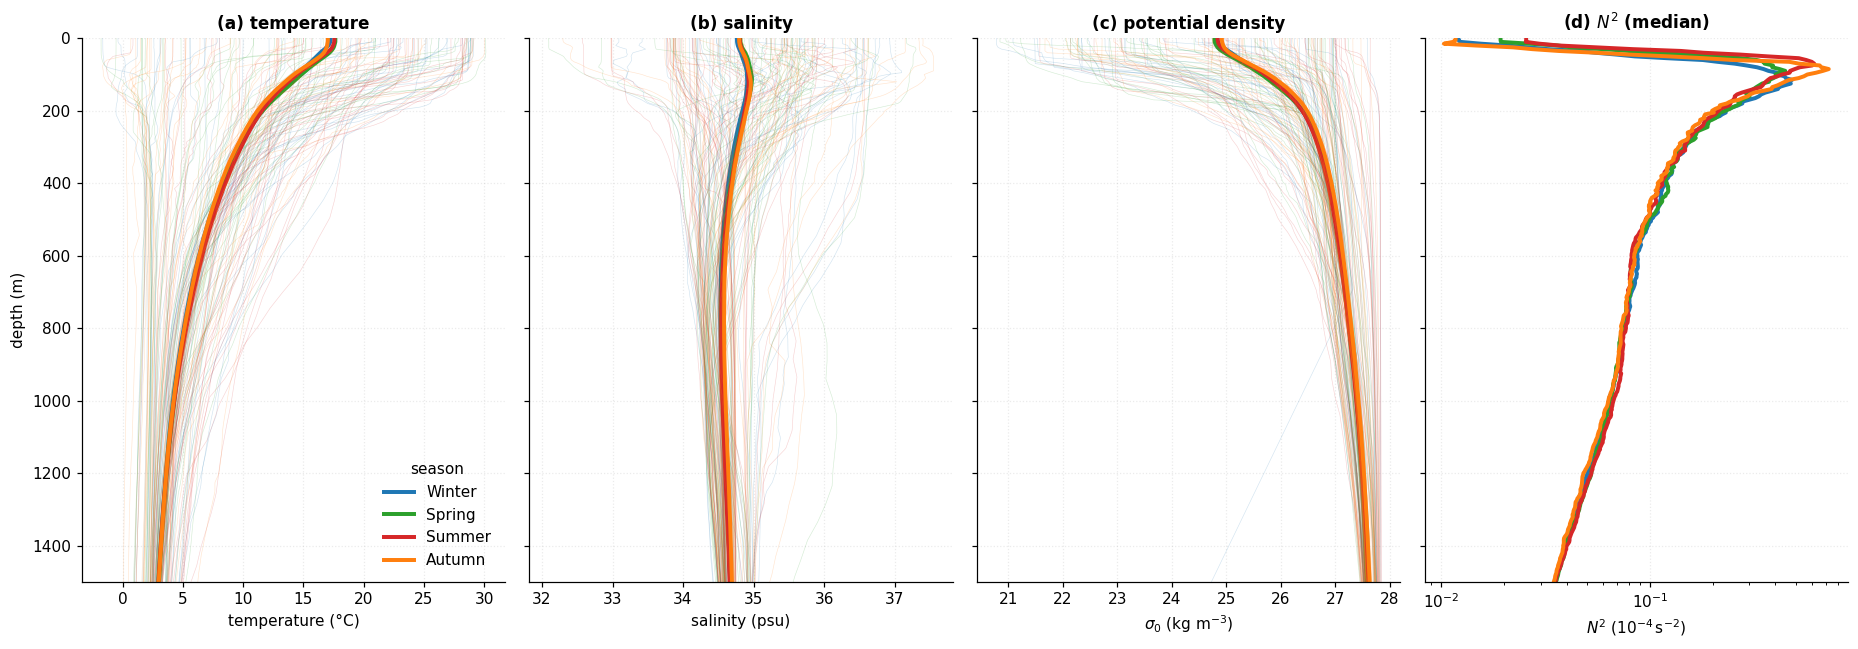

,profiles,median MLD (m),90th pct MLD (m),depth of max median N² (m),max median N²
season,,,,,
Winter,651,60.0,170.0,115.0,0.480
Spring,612,50.0,169.5,90.0,0.446
Summer,591,45.0,105.0,70.0,0.613
Autumn,646,55.0,125.0,85.0,0.720


In [27]:
season_order  = ["Winter", "Spring", "Summer", "Autumn"]
season_colour = {"Winter": "#1f77b4", "Spring": "#2ca02c", "Summer": "#d62728", "Autumn": "#ff7f0e"}
season_prof   = prof.SEASON.to_numpy()
rng_plot = np.random.default_rng(7)

fields = [("TEMP", T, "temperature (°C)", np.nanmean), ("PSAL", S, "salinity (psu)", np.nanmean),
          ("SIG0", SIG, "$\\sigma_0$ (kg m$^{-3}$)", np.nanmean), ("BRV2", N2, N2_LABEL, np.nanmedian)]

fig, axes = plt.subplots(1, 4, figsize=(17, 6), sharey=True)
for ax, (name, arr, lab, stat) in zip(axes, fields):
    for se in season_order:
        rows = np.flatnonzero(season_prof == se)
        if rows.size == 0: continue
        if name != "BRV2":
            for j in rng_plot.choice(rows, size=min(40, rows.size), replace=False):
                ax.plot(arr[j], depth_all, color=season_colour[se], lw=0.4, alpha=0.2)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = stat(arr[rows], axis=0)
        if name == "BRV2": m = np.where(m > 0, m, np.nan)
        ax.plot(m, depth_all, color=season_colour[se], lw=2.6, label=se)
    ax.set_xlabel(lab); ax.set_ylim(1500, 0)
axes[3].set_xscale("log")
axes[0].set_ylabel("depth (m)")
for ax, t in zip(axes, ["(a) temperature", "(b) salinity", "(c) potential density", "(d) $N^2$ (median)"]): ax.set_title(t)
axes[0].legend(loc="lower right", title="season")
plt.tight_layout(); save(fig, "fig4_seasonal_profiles"); plt.show()

# --- numbers behind the figure: mixed-layer depth and N^2 maximum per season ----------------------
mld = mixed_layer_depth(SIG, depth_all)
rows_tab = []
for se in season_order:
    rows = np.flatnonzero(season_prof == se)
    if rows.size == 0: continue
    med_n2 = np.nanmedian(N2[rows], axis=0)
    ok_lvl = depth_all >= 20
    k = np.nanargmax(np.where(ok_lvl, med_n2, np.nan))
    rows_tab.append({"season": se, "profiles": rows.size,
                     "median MLD (m)": np.nanmedian(mld[rows]), "90th pct MLD (m)": np.nanpercentile(mld[rows], 90),
                     "depth of max median N² (m)": depth_all[k], "max median N²": med_n2[k]})
season_tab = pd.DataFrame(rows_tab).set_index("season").round(3)
season_tab

The last diagnostic of this section is the annual cycle of the mixed-layer depth (MLD) itself, computed per profile with the density-threshold criterion above and summarised per month by its median and interquartile range. The MLD is the single most important quantity for the vertical structure of $N^2$, because $N^2$ is small inside the mixed layer and jumps up just below it.

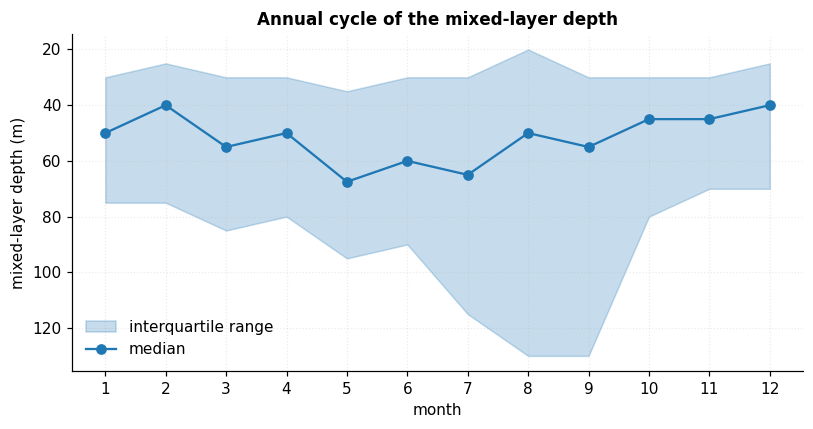

The median mixed-layer depth is largest in month 5 (68 m) and smallest in month 2 (40 m). Individual profiles scatter widely around these medians, with an interquartile range of up to 110 m within a single month. The criterion could be applied to 100 % of the sampled profiles; the others either lack a value at the 10 m reference level or never cross the threshold, so the statistics above describe the profiles where the method works.

In [29]:
month_prof = prof.MONTH.to_numpy()
mld_by_month = [mld[(month_prof == m) & np.isfinite(mld)] for m in range(1, 13)]
med = np.array([np.median(v) if v.size else np.nan for v in mld_by_month])
q25 = np.array([np.percentile(v, 25) if v.size else np.nan for v in mld_by_month])
q75 = np.array([np.percentile(v, 75) if v.size else np.nan for v in mld_by_month])

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.fill_between(range(1, 13), q25, q75, color="C0", alpha=0.25, label="interquartile range")
ax.plot(range(1, 13), med, "o-", color="C0", label="median")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("mixed-layer depth (m)"); ax.invert_yaxis()
ax.set_title("Annual cycle of the mixed-layer depth"); ax.legend()
plt.tight_layout(); save(fig, "fig5_mld_cycle"); plt.show()

deep, shallow = np.nanargmax(med) + 1, np.nanargmin(med) + 1
display(Markdown(
    f"The median mixed-layer depth is largest in month {deep} ({np.nanmax(med):.0f} m) and smallest in month {shallow} ({np.nanmin(med):.0f} m). Individual profiles scatter widely around these medians, with an interquartile range of up to {np.nanmax(q75 - q25):.0f} m within a single month. "
    f"The criterion could be applied to {100 * np.isfinite(mld).mean():.0f} % of the sampled profiles; the others either lack a value at the 10 m reference level or never cross the threshold, so the statistics above describe the profiles where the method works."))

---
<a id="s4"></a>
# 4. Machine-learning experiment: predicting $N^2$

## a) Set-up: features, target and a leakage-free split

Every row of the table is one (profile, depth) pair, and the 60 or so rows of one profile are strongly related to each other (same float, same day, same water mass). If rows were split into training and test sets at random, neighbouring levels of the *same profile* would end up on both sides, and the test score would measure how well the model interpolates within a profile rather than how well it predicts a new one. I therefore split **by profile**: 75 % of the profiles (all of their levels) are used for training and tuning, 25 % are held back and only touched once, for the final test (Roberts et al., 2017). The same grouping is used inside all cross-validation below.

In [31]:
TARGET = "BRV2"
X = df[FEATURES].to_numpy(float)
y = df[TARGET].to_numpy(float)
groups = df["PROF"].to_numpy()

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=RNG_SEED)
tr, te = next(gss.split(X, y, groups))
Xtr, Xte, ytr, yte, gtr = X[tr], X[te], y[tr], y[te], groups[tr]

assert not set(groups[tr]) & set(groups[te]), "profile leakage between train and test!"
print(f"Features : {FEATURES}")
print(f"Train    : {len(tr):>8,} rows | {np.unique(gtr).size:>5,} profiles")
print(f"Test     : {len(te):>8,} rows | {np.unique(groups[te]).size:>5,} profiles")

Features : ['DEPTH', 'TEMP', 'PSAL', 'LATITUDE', 'LONGITUDE', 'SIN_DOY', 'COS_DOY']
Train    :  118,078 rows | 1,875 profiles
Test     :   39,369 rows |   625 profiles


## b) Models and hyper-parameter tuning

The linear models are wrapped in a pipeline that standardises the predictors first (zero mean, unit variance), because the ridge/lasso/elastic-net penalties treat all coefficients equally and would otherwise depend on the arbitrary units of each variable (metres of depth versus degrees of latitude, say). The tree ensembles do not need scaling.

Hyper-parameters are chosen with **grouped 4-fold cross-validation on the training profiles only**, maximising R²; the test profiles play no role in this. The grids are deliberately small so the notebook stays affordable to run:

| model | tuned |
|---|---|
| Ridge | penalty $\alpha$ |
| Lasso | penalty $\alpha$ |
| Elastic net | $\alpha$ and $L^1$ share $\rho$ |
| Random forest | minimum samples per leaf (150 trees) |
| Gradient boosting | learning rate $\eta$, maximum leaf nodes (300 iterations) |

In [33]:
def make_models(seed=RNG_SEED):
    return {
        "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge":            make_pipeline(StandardScaler(), Ridge()),
        "Lasso":            make_pipeline(StandardScaler(), Lasso(max_iter=20000)),
        "ElasticNet":       make_pipeline(StandardScaler(), ElasticNet(max_iter=20000)),
        "RandomForest":     RandomForestRegressor(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=seed),
        "GradientBoosting": HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=seed),
    }

GRIDS = {
    "Ridge":            {"ridge__alpha": [1e-3, 1e-1, 1, 10, 100, 1000]},
    "Lasso":            {"lasso__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]},
    "ElasticNet":       {"elasticnet__alpha": [1e-4, 1e-3, 1e-2, 1e-1], "elasticnet__l1_ratio": [0.2, 0.5, 0.8]},
    "RandomForest":     {"min_samples_leaf": [3, 10, 30]},
    "GradientBoosting": {"learning_rate": [0.05, 0.15], "max_leaf_nodes": [15, 63]},
}

tuned, tuning_log = {}, []
t0 = time.time()
for name, est in make_models().items():
    if name in GRIDS:
        gs = GridSearchCV(est, GRIDS[name], cv=GroupKFold(n_splits=4), scoring="r2", n_jobs=1, refit=False)
        gs.fit(Xtr, ytr, groups=gtr)
        best = int(np.argmax(gs.cv_results_["mean_test_score"]))
        params = gs.cv_results_["params"][best]
        tuned[name] = clone(est).set_params(**params)
        tuning_log.append({"model": name, "best parameters": {k.split("__")[-1]: v for k, v in params.items()},
                           "grouped-CV R²": round(float(gs.cv_results_["mean_test_score"][best]), 4)})
    else:
        tuned[name] = clone(est)
        tuning_log.append({"model": name, "best parameters": "-", "grouped-CV R²": np.nan})
    print(f"  tuned {name:<17s} ({time.time() - t0:5.0f} s elapsed)")
pd.DataFrame(tuning_log).set_index("model")

  tuned LinearRegression  (    0 s elapsed)
  tuned Ridge             (    0 s elapsed)
  tuned Lasso             (    1 s elapsed)
  tuned ElasticNet        (    2 s elapsed)
  tuned RandomForest      (  115 s elapsed)
  tuned GradientBoosting  (  179 s elapsed)


,best parameters,grouped-CV R²
model,,
LinearRegression,-,NaN
Ridge,{'alpha': 100},0.2248
Lasso,{'alpha': 0.001},0.2248
ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",0.2248
RandomForest,{'min_samples_leaf': 10},0.5754
GradientBoosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 63}",0.5840


## c) How stable is the model ranking? Repeated grouped cross-validation

A single train/validation split can give a misleading ranking by luck of the draw. To see how much the scores fluctuate, the tuned models are refitted on `N_CV_REPEATS` different random splits of the *training profiles* (again grouped by profile, 75 % / 25 %), and the R² and MAE of each fit on its held-out profiles are collected. The box plots show the median, interquartile range and outliers over the repeats.

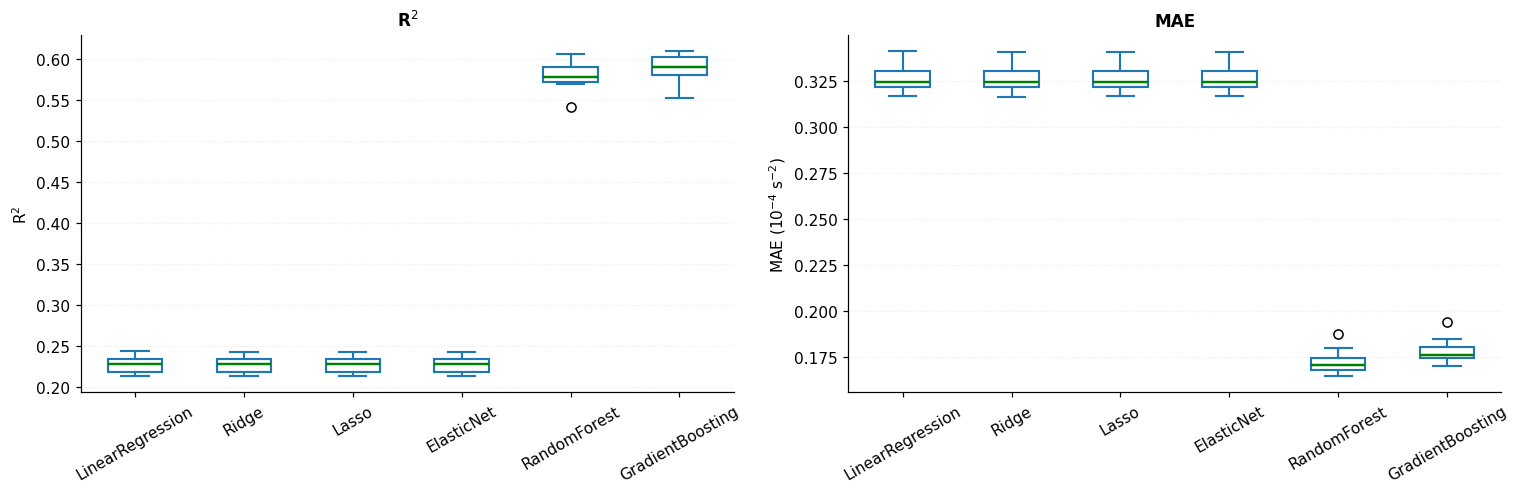

                  R2_mean  R2_std  MAE_mean  MAE_std
model                                               
LinearRegression   0.2273  0.0104    0.3270   0.0086
Ridge              0.2273  0.0103    0.3269   0.0085
Lasso              0.2274  0.0102    0.3269   0.0085
ElasticNet         0.2274  0.0102    0.3269   0.0085
RandomForest       0.5783  0.0190    0.1722   0.0076
GradientBoosting   0.5880  0.0185    0.1781   0.0079


Over 8 repeated splits the highest mean R$^2$ is obtained by GradientBoosting (0.588 $\pm$ 0.018, MAE 0.178) and the lowest by LinearRegression (0.227 $\pm$ 0.010). The best linear model reaches 0.227 and the best tree ensemble 0.588, so the tree ensembles are ahead by 0.361. The split-to-split standard deviation (at most 0.019) is small next to this gap. The four linear models are nearly indistinguishable, which is what one expects when there are many rows and only seven, fairly well-determined, predictors: the penalty has little to do.

In [35]:
cv_rows = []
splitter = GroupShuffleSplit(n_splits=N_CV_REPEATS, test_size=0.25, random_state=RNG_SEED + 1)
for k, (a, b) in enumerate(splitter.split(Xtr, ytr, gtr)):
    for name, est in tuned.items():
        m = clone(est).fit(Xtr[a], ytr[a])
        cv_rows.append({"model": name, "repeat": k, **evaluate(ytr[b], m.predict(Xtr[b]))})
cv_df = pd.DataFrame(cv_rows)
model_order = list(tuned)

def boxpanel(ax, metric):
    sns.boxplot(data=cv_df, x="model", y=metric, order=model_order, ax=ax, width=0.5, color="white",
                boxprops=dict(edgecolor="#1f77b4", linewidth=1.4), medianprops=dict(color="green", linewidth=1.6),
                whiskerprops=dict(color="#1f77b4", linewidth=1.4), capprops=dict(color="#1f77b4", linewidth=1.4),
                flierprops=dict(marker="o", markerfacecolor="none", markeredgecolor="k", markersize=6))
    ax.set_title("R$^2$" if metric == "R2" else "MAE")
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
boxpanel(axes[0], "R2"); axes[0].set_ylabel("R$^2$")
boxpanel(axes[1], "MAE"); axes[1].set_ylabel("MAE" + (r" ($10^{-4}$ s$^{-2}$)" if BRV2_SCALE != 1 else ""))
plt.tight_layout(); save(fig, "fig6_cv_boxplots"); plt.show()

summ = cv_df.groupby("model").agg(R2_mean=("R2", "mean"), R2_std=("R2", "std"),
                                  MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std")).loc[model_order].round(4)
print(summ.to_string())

is_tree = lambda n: n in ("RandomForest", "GradientBoosting")
b_cv, w_cv = summ.R2_mean.idxmax(), summ.R2_mean.idxmin()
lin_best = summ.loc[[m for m in model_order if not is_tree(m)], "R2_mean"].max()
tree_best = summ.loc[[m for m in model_order if is_tree(m)], "R2_mean"].max()
display(Markdown(
    f"Over {N_CV_REPEATS} repeated splits the highest mean R$^2$ is obtained by {b_cv} ({summ.R2_mean[b_cv]:.3f} $\\pm$ {summ.R2_std[b_cv]:.3f}, MAE {summ.MAE_mean[b_cv]:.3f}) and the lowest by {w_cv} ({summ.R2_mean[w_cv]:.3f} $\\pm$ {summ.R2_std[w_cv]:.3f}). "
    f"The best linear model reaches {lin_best:.3f} and the best tree ensemble {tree_best:.3f}, so the tree ensembles are {'ahead' if tree_best > lin_best else 'not ahead'} by {abs(tree_best - lin_best):.3f}. "
    f"The split-to-split standard deviation (at most {summ.R2_std.max():.3f}) is {'small next to' if summ.R2_std.max() < abs(tree_best - lin_best) else 'about as large as'} this gap. "
    f"The four linear models are nearly indistinguishable, which is what one expects when there are many rows and only seven, fairly well-determined, predictors: the penalty has little to do."))

## d) Final test on unseen profiles

Now each tuned model is fitted **once** on all training profiles and evaluated on the 25 % of profiles that have never been used for fitting or tuning. This is the number I would quote as the performance for a new profile.

In [39]:
fitted, pred_te, test_rows = {}, {}, []
for name, est in tuned.items():
    t0 = time.time()
    m = clone(est).fit(Xtr, ytr)
    fitted[name] = m
    pred_te[name] = m.predict(Xte)
    test_rows.append({"model": name, **evaluate(yte, pred_te[name]), "fit time (s)": time.time() - t0})
test_tbl = pd.DataFrame(test_rows).set_index("model").round(4)
test_tbl

,R2,MAE,RMSE,fit time (s)
model,,,,
LinearRegression,0.2372,0.3135,0.6978,0.0234
Ridge,0.2373,0.3134,0.6978,0.0177
Lasso,0.2376,0.3133,0.6976,0.0312
ElasticNet,0.2376,0.3133,0.6976,0.0327
RandomForest,0.6178,0.1529,0.4940,11.8952
GradientBoosting,0.6241,0.1585,0.4899,6.7950


The scatter plots below compare the predicted and observed $N^2$ on the test profiles for the plain linear regression and the two tree ensembles. Because there are over a hundred thousand test points, I draw them as a two-dimensional histogram (log colour scale) rather than as a cloud of overlapping dots. A perfect model would put all the density on the dashed 1:1 line.

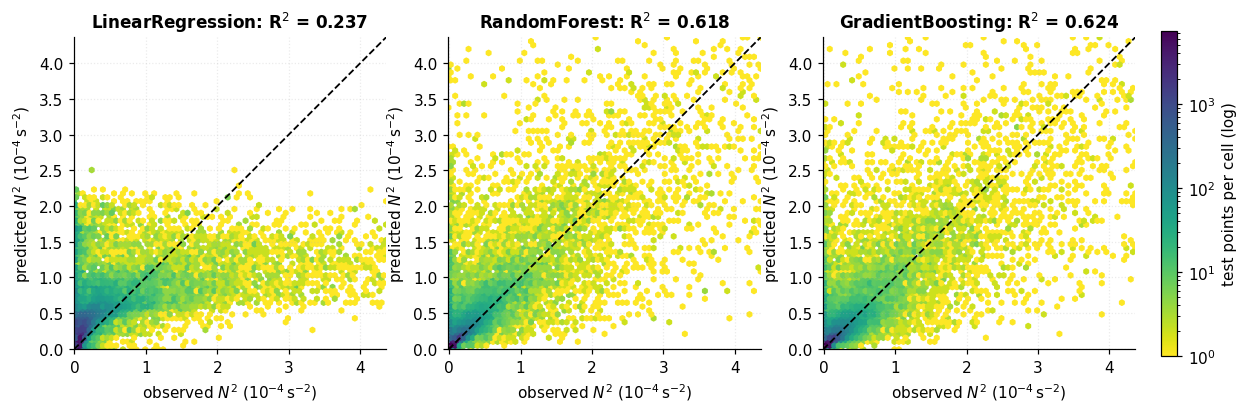

On the held-out profiles GradientBoosting performs best (R$^2$ = 0.624, MAE = 0.159, against R$^2$ = 0.237 for plain linear regression. The winning model is in the same family as the winner of the repeated cross-validation (GradientBoosting), so the two tests tell the same story. 2.3 % of the observed test values of $N^2$ are negative. The linear model predicts negative values for 21.2 % of the rows, random forest for 0.0 % and gradient boosting for 1.3 %.

In [41]:
show = ["LinearRegression", "RandomForest", "GradientBoosting"]
lo = min(0.0, float(np.percentile(yte, 0.5)))
hi = float(np.percentile(np.concatenate([yte] + [pred_te[n] for n in show]), 99.5))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, name in zip(axes, show):
    hb = ax.hexbin(yte, pred_te[name], gridsize=70, extent=(lo, hi, lo, hi), bins="log", mincnt=1, cmap="viridis_r")
    ax.plot([lo, hi], [lo, hi], "k--", lw=1.2)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="observed " + N2_LABEL, ylabel="predicted " + N2_LABEL,
           title=f"{name}: R$^2$ = {test_tbl.loc[name, 'R2']:.3f}")
    ax.set_aspect("equal", adjustable="box")
fig.colorbar(hb, ax=axes, shrink=0.8, pad=0.02).set_label("test points per cell (log)")
save(fig, "fig7_truth_vs_prediction"); plt.show()

b_te = test_tbl.R2.idxmax()
neg = {n: float((pred_te[n] < 0).mean()) for n in show}
agree = is_tree(b_te) == is_tree(b_cv)
display(Markdown(
    f"On the held-out profiles {b_te} performs best (R$^2$ = {test_tbl.R2[b_te]:.3f}, MAE = {test_tbl.MAE[b_te]:.3f}, against R$^2$ = {test_tbl.R2['LinearRegression']:.3f} for plain linear regression. "
    f"The winning model is {'in the same family as' if agree else 'from a different family than'} the winner of the repeated cross-validation ({b_cv}), so the two tests {'tell the same story' if agree else 'disagree, and I would not trust either ranking without further checks'}. "
    f"{100 * (yte < 0).mean():.1f} % of the observed test values of $N^2$ are negative. The linear model predicts negative values for {100 * neg['LinearRegression']:.1f} % of the rows, random forest for {100 * neg['RandomForest']:.1f} % and gradient boosting for {100 * neg['GradientBoosting']:.1f} %."))

## e) Where do the models fail? Error as a function of depth

A single R² hides *where* the errors are made. $N^2$ is highly non-uniform in the vertical (concentrated in the thermocline), so a model can score well overall while being poor in the deep ocean, or the other way round. The figure bins the test rows by depth and shows (a) the mean observed $N^2$, (b) the mean absolute error of each model, and (c) the MAE divided by the mean observed $N^2$ in that bin, i.e. the *relative* error, which shows where the models are useful in relative terms.

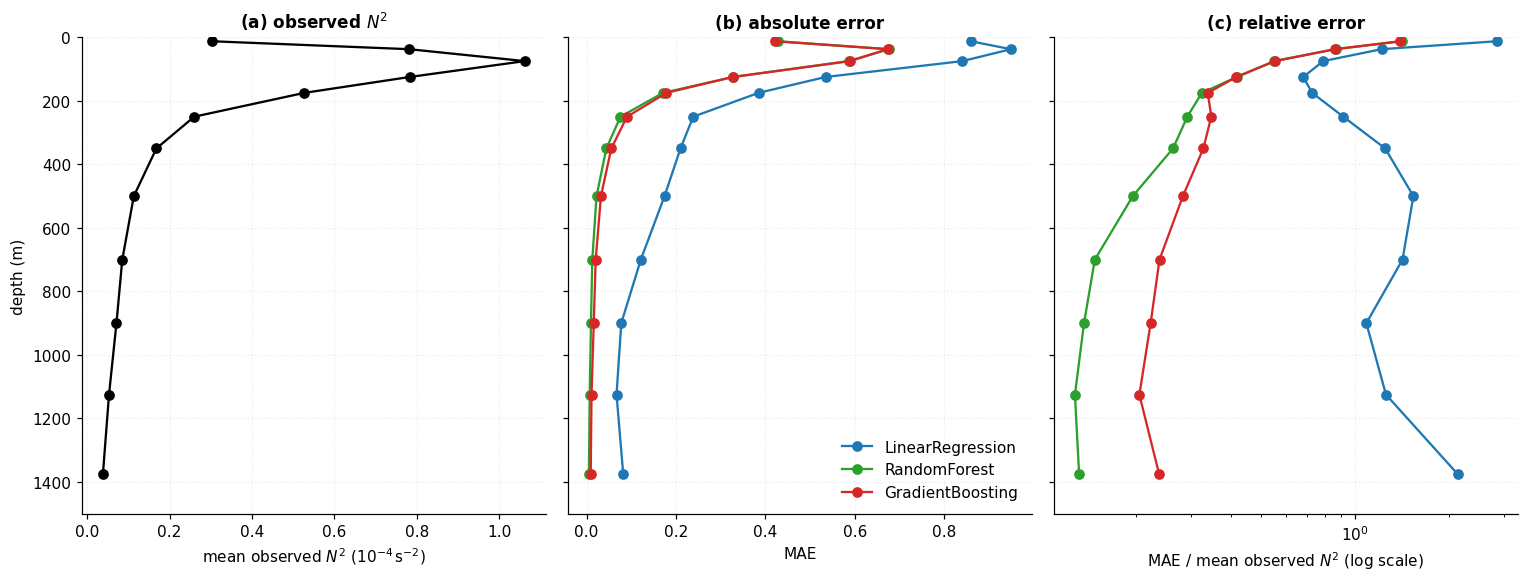

Mean observed $N^2$ is largest in the 50 to 100 m bin (1.06). For GradientBoosting the absolute error is largest in the 25 to 50 m bin (MAE 0.67), so the overall R$^2$ is mostly a statement about the upper ocean. Relative to the mean observed value the error is largest in the 0 to 25 m bin, at 1.39 times the mean; where the signal is close to zero even a small absolute error is large in relative terms.

In [44]:
edges = np.array([0, 25, 50, 100, 150, 200, 300, 400, 600, 800, 1000, 1250, 1501])
depth_te = Xte[:, FEATURES.index("DEPTH")]
bin_id = pd.cut(depth_te, edges, include_lowest=True)
centre = 0.5 * (edges[:-1] + edges[1:])

obs_mean = pd.Series(yte).groupby(bin_id, observed=False).mean().to_numpy()
mae_bin = {n: pd.Series(np.abs(yte - pred_te[n])).groupby(bin_id, observed=False).mean().to_numpy() for n in show}

fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), sharey=True)
axes[0].plot(obs_mean, centre, "ko-"); axes[0].set_xlabel("mean observed " + N2_LABEL); axes[0].set_title("(a) observed $N^2$")
for n, c in zip(show, ["C0", "C2", "C3"]):
    axes[1].plot(mae_bin[n], centre, "o-", color=c, label=n)
    axes[2].plot(mae_bin[n] / np.abs(obs_mean), centre, "o-", color=c, label=n)
axes[1].set_xlabel("MAE"); axes[1].set_title("(b) absolute error"); axes[1].legend()
axes[2].set_xlabel("MAE / mean observed $N^2$ (log scale)"); axes[2].set_xscale("log"); axes[2].set_title("(c) relative error")
axes[0].set_ylabel("depth (m)"); axes[0].set_ylim(1500, 0)
plt.tight_layout(); save(fig, "fig8_error_by_depth"); plt.show()

k_peak = int(np.nanargmax(obs_mean))
best_tree = max(["RandomForest", "GradientBoosting"], key=lambda n: test_tbl.R2[n])
k_worst = int(np.nanargmax(mae_bin[best_tree]))
k_rel = int(np.nanargmax(mae_bin[best_tree] / np.abs(obs_mean)))
display(Markdown(
    f"Mean observed $N^2$ is largest in the {edges[k_peak]:.0f} to {edges[k_peak + 1]:.0f} m bin ({obs_mean[k_peak]:.2f}). For {best_tree} the absolute error is largest in the {edges[k_worst]:.0f} to {edges[k_worst + 1]:.0f} m bin (MAE {mae_bin[best_tree][k_worst]:.2f})"
    f"{', so the overall R$^2$ is mostly a statement about the upper ocean' if edges[k_worst + 1] <= 300 else ''}. "
    f"Relative to the mean observed value the error is largest in the {edges[k_rel]:.0f} to {edges[k_rel + 1]:.0f} m bin, at {mae_bin[best_tree][k_rel] / abs(obs_mean[k_rel]):.2f} times the mean; where the signal is close to zero even a small absolute error is large in relative terms."))

## f) Which predictors matter? Permutation importance

To see which inputs the models rely on, I use **permutation importance**: shuffle one predictor at a time in the test data, breaking its link with the target, and record how much R² drops (repeated five times; a random sample of up to 30,000 test rows keeps this affordable). A large drop means the model needs that predictor. Unlike the built-in impurity importances of tree models, this is computed on unseen data and can be applied to any model, so the three models are directly comparable.

One caveat: `TEMP`, `PSAL` and `DEPTH` are correlated (section 3b), so when one of them is shuffled the model can partly compensate with the others. The importances are therefore best read as a ranking of *how much the model leans on each input*, not as a clean decomposition of the physics.

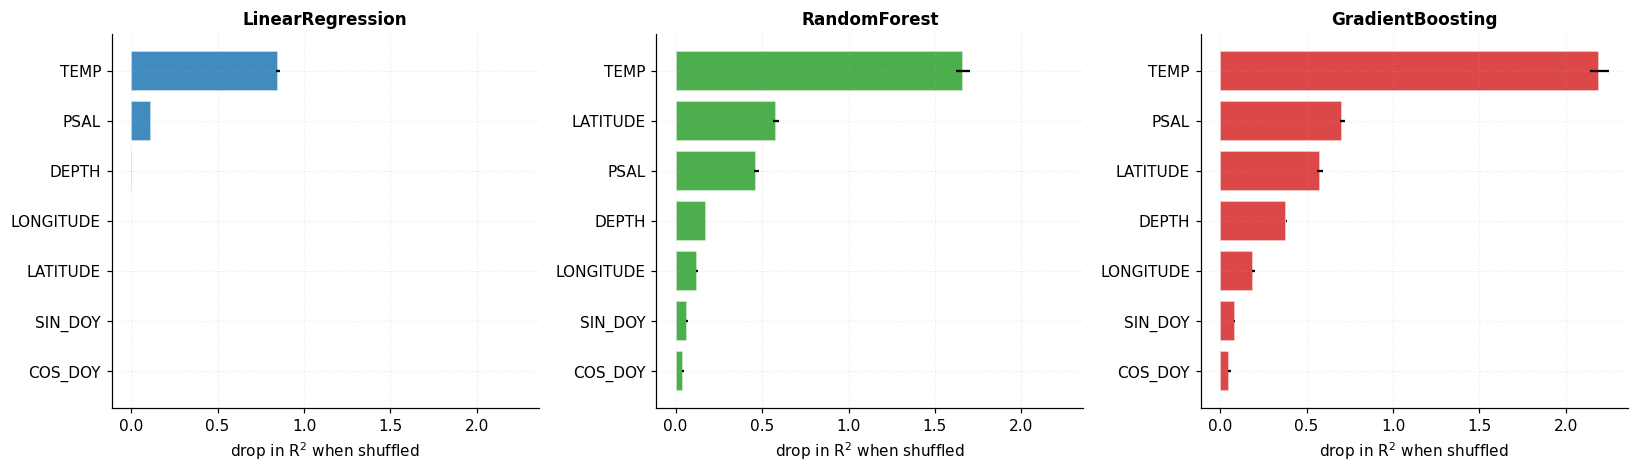

Ranked by the drop in R$^2$ when shuffled, the leading predictors are TEMP (0.848), PSAL (0.114), DEPTH (0.004) for LinearRegression; TEMP (1.662), LATITUDE (0.581), PSAL (0.467) for RandomForest; TEMP (2.194), PSAL (0.707), LATITUDE (0.577) for GradientBoosting. Position carries some weight (largest drop 0.581).

In [46]:
rs = np.random.default_rng(RNG_SEED + 2)
sub = rs.choice(len(yte), size=min(30000, len(yte)), replace=False)
imp = {}
for n in show:
    r = permutation_importance(fitted[n], Xte[sub], yte[sub], n_repeats=5, scoring="r2", random_state=RNG_SEED, n_jobs=1)
    imp[n] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=FEATURES)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True)
for ax, n, c in zip(axes, show, ["C0", "C2", "C3"]):
    d = imp[n].sort_values("mean")
    ax.barh(d.index, d["mean"], xerr=d["std"], color=c, alpha=0.85, edgecolor="white")
    ax.set_title(n); ax.set_xlabel("drop in R$^2$ when shuffled")
plt.tight_layout(); save(fig, "fig9_permutation_importance"); plt.show()

top = {n: imp[n]["mean"].sort_values(ascending=False) for n in show}
display(Markdown(
    "Ranked by the drop in R$^2$ when shuffled, the leading predictors are " +
    "; ".join(f"{', '.join(f'{k} ({v:.3f})' for k, v in top[n].head(3).items())} for {n}" for n in show) + ". "
    f"Position carries {'very little' if max(imp[n].loc[['LATITUDE', 'LONGITUDE'], 'mean'].max() for n in show) < 0.05 else 'some'} weight (largest drop {max(imp[n].loc[['LATITUDE', 'LONGITUDE'], 'mean'].max() for n in show):.3f})."))

---
<a id="s5"></a>
# 5. Robustness checks and a physics-informed extension

## a) Does a random split flatter the models? A time-blocked test

Splitting by profile removes the leakage between levels of one profile, but profiles from the same float measured a few days apart are still very similar, and the archive contains many such neighbours. A stricter test is to **train on the earlier 75 % of the record and test on the later 25 %**, so the models are asked to predict a period they have never seen (a real forecasting-style situation; Roberts et al., 2017). I reuse the hyper-parameters tuned above (no retuning), so any difference in skill comes from the split, not from the tuning.

Argo coverage changes over time (floats are added, positions change, section 3a), so this test also mixes in distribution shift; a lower score here is a genuine limitation for use on future data, not just a technicality.

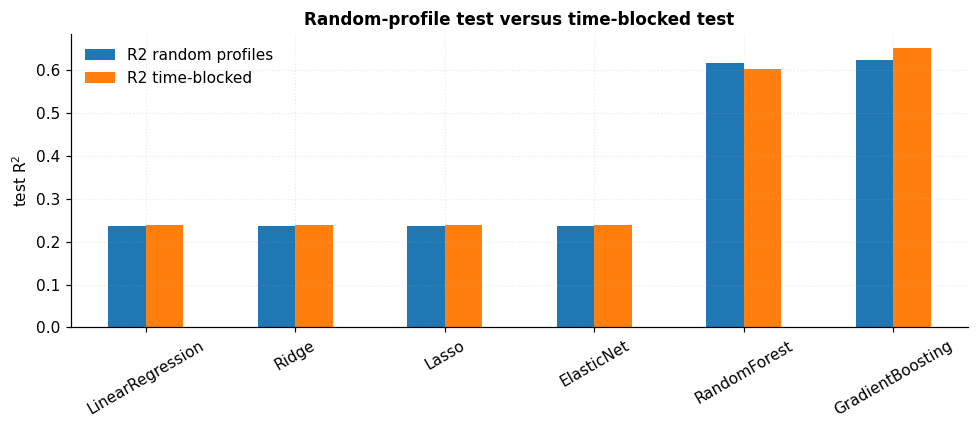

Training on profiles before 2012-04-22 (118,082 rows) and testing on later ones (39,365 rows) gives the best R$^2$ for GradientBoosting (0.652). Compared with the random-profile test the change in R$^2$ ranges from -0.014 to +0.027 across models (negative means worse on the later period). The ranking of the two model families does not change.

,R2 time-blocked,R2 random profiles
model,,
LinearRegression,0.2383,0.2372
Ridge,0.2382,0.2373
Lasso,0.2381,0.2376
ElasticNet,0.2381,0.2376
RandomForest,0.6036,0.6178
GradientBoosting,0.6516,0.6241


In [49]:
t_cut = df["TIME"].sort_values().iloc[int((1 - TEST_FRACTION) * len(df))]
is_early = (df["TIME"] < t_cut).to_numpy()
tr_t, te_t = np.flatnonzero(is_early), np.flatnonzero(~is_early)

tb_rows = []
for name, est in tuned.items():
    m = clone(est).fit(X[tr_t], y[tr_t])
    tb_rows.append({"model": name, "R2 time-blocked": r2_score(y[te_t], m.predict(X[te_t]))})
tb = pd.DataFrame(tb_rows).set_index("model")
tb["R2 random profiles"] = test_tbl["R2"]

ax = tb[["R2 random profiles", "R2 time-blocked"]].plot.bar(figsize=(9, 4), color=["C0", "C1"], rot=30)
ax.set_ylabel("test R$^2$"); ax.set_xlabel(""); ax.set_title("Random-profile test versus time-blocked test")
plt.tight_layout(); save(ax.figure, "fig10_time_blocked"); plt.show()

drop = (tb["R2 random profiles"] - tb["R2 time-blocked"])
display(Markdown(
    f"Training on profiles before {pd.Timestamp(t_cut).date()} ({len(tr_t):,} rows) and testing on later ones ({len(te_t):,} rows) gives the best R$^2$ for {tb['R2 time-blocked'].idxmax()} ({tb['R2 time-blocked'].max():.3f}). "
    f"Compared with the random-profile test the change in R$^2$ ranges from {-drop.max():+.3f} to {-drop.min():+.3f} across models (negative means worse on the later period). "
    f"{'The ranking of the two model families does not change.' if is_tree(tb['R2 time-blocked'].idxmax()) == is_tree(b_te) else 'The best model family changes under this stricter split.'}"))
tb.round(4)

## b) Extension: what if the vertical gradients are supplied?

*(Spoiler for the impatient: this is the machine-learning equivalent of handing a student the answer key.)*

The equation in section 1 says that $N^2$ is, to good approximation, a *linear* function of $\partial T/\partial d$ and $\partial S/\partial d$:

\begin{equation*}
N^2 \approx g\,\beta\,\frac{\partial S}{\partial d} - g\,\alpha\,\frac{\partial T}{\partial d}.
\end{equation*}

The baseline models never see these gradients, only the local values of $T$ and $S$. I now add `DTDZ` and `DSDZ` (computed from each profile on the native 5 m grid, section 2c) as two extra predictors and refit the same models with the same hyper-parameters. This changes the problem from "estimate stratification from the state at one level" to "estimate it from the local structure of the profile", which is a fundamentally easier task, so the purpose is to show how much of the earlier difficulty was missing information rather than missing model flexibility.

As a physical sanity check I also fit a two-predictor linear regression on the gradients alone and compare its coefficients with the theoretical values $g\beta$ and $-g\alpha$ (evaluated with nominal surface values of $\alpha=1.7\times10^{-4}\ \mathrm{K^{-1}}$ and $\beta=7.6\times10^{-4}\ \mathrm{psu^{-1}}$, and converted to the units used for $N^2$ above). Since $\alpha$ decreases with depth in the real ocean, exact agreement is not expected, only the right signs and order of magnitude.

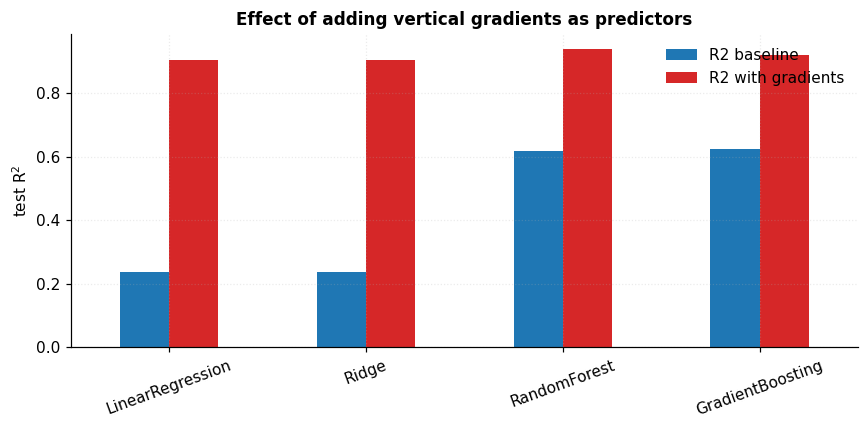

      fitted coefficient  theory (nominal α, β)  R2 (gradients only, test)
DTDZ             -23.835                -16.677                      0.897
DSDZ              77.938                 74.556                      0.897


Adding the two gradients raises the best test R$^2$ from 0.624 (GradientBoosting, baseline) to 0.938 (RandomForest). A linear regression on the gradients alone gives R$^2$ = 0.897. Its coefficients have the expected signs (negative for temperature, positive for salinity) and are 1.43 and 1.05 times the theoretical values.

,R2 baseline,R2 with gradients,MAE baseline,MAE with gradients
model,,,,
LinearRegression,0.2372,0.9027,0.3135,0.1046
Ridge,0.2373,0.9027,0.3134,0.1046
RandomForest,0.6178,0.9381,0.1529,0.0423
GradientBoosting,0.6241,0.9191,0.1585,0.0519


In [53]:
FEATURES_PLUS = FEATURES + ["DTDZ", "DSDZ"]
Xp = df[FEATURES_PLUS].to_numpy(float)

ext_rows = []
for name in ["LinearRegression", "Ridge", "RandomForest", "GradientBoosting"]:
    m = clone(tuned[name]).fit(Xp[tr], y[tr])
    ext_rows.append({"model": name, "R2 baseline": test_tbl.loc[name, "R2"], "R2 with gradients": r2_score(y[te], m.predict(Xp[te])),
                     "MAE baseline": test_tbl.loc[name, "MAE"], "MAE with gradients": mean_absolute_error(y[te], m.predict(Xp[te]))})
ext = pd.DataFrame(ext_rows).set_index("model")

ax = ext[["R2 baseline", "R2 with gradients"]].plot.bar(figsize=(8, 4), color=["C0", "C3"], rot=20)
ax.set_ylabel("test R$^2$"); ax.set_xlabel(""); ax.set_title("Effect of adding vertical gradients as predictors")
plt.tight_layout(); save(ax.figure, "fig11_gradient_extension"); plt.show()

# two-predictor physical check on the gradients alone
lin2 = LinearRegression().fit(df.loc[tr, ["DTDZ", "DSDZ"]], y[tr])
theory = {"DTDZ": -GRAV * ALPHA_T * BRV2_SCALE, "DSDZ": GRAV * BETA_S * BRV2_SCALE}
phys = pd.DataFrame({"fitted coefficient": dict(zip(["DTDZ", "DSDZ"], lin2.coef_)), "theory (nominal α, β)": theory})
phys["R2 (gradients only, test)"] = r2_score(y[te], lin2.predict(df.loc[te, ["DTDZ", "DSDZ"]]))
print(phys.round(3).to_string())

best_ext = ext["R2 with gradients"].idxmax()
display(Markdown(
    f"Adding the two gradients raises the best test R$^2$ from {test_tbl.R2.max():.3f} ({b_te}, baseline) to {ext['R2 with gradients'].max():.3f} ({best_ext}). A linear regression on the gradients alone gives R$^2$ = {phys['R2 (gradients only, test)'].iloc[0]:.3f}. "
    f"Its coefficients have the {'expected' if (lin2.coef_[0] < 0 < lin2.coef_[1]) else 'unexpected'} signs (negative for temperature, positive for salinity) and are {lin2.coef_[0] / theory['DTDZ']:.2f} and {lin2.coef_[1] / theory['DSDZ']:.2f} times the theoretical values."))
ext.round(4)

## c) How sure am I? A bootstrap over profiles

A single R$^2$ on one test set has no error bar, and the rows of a profile are not independent, so the usual formulas for a confidence interval do not apply. I resample the **test profiles** with replacement (a cluster bootstrap, 500 draws; each draw keeps all levels of a profile together) and recompute R$^2$ each time. The same draws are used for every model, which also allows a paired interval for the difference between the best tree ensemble and the best linear model.

To keep this cheap, each profile is reduced to four sums (row count, $\sum y$, $\sum y^2$ and the summed squared error), from which R$^2$ of any resample follows directly.

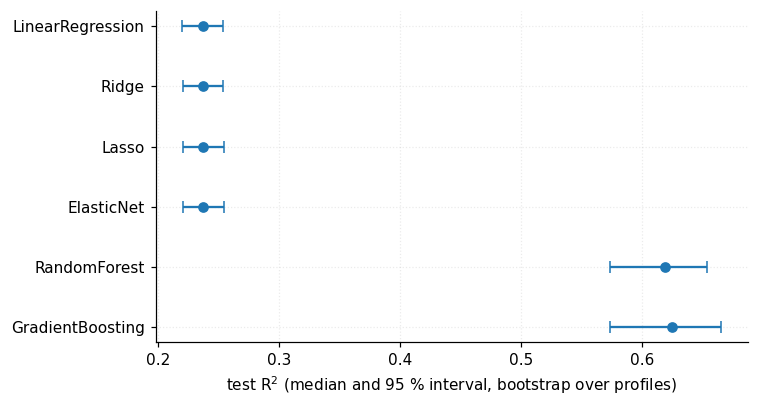

                  2.5 %  median  97.5 %
LinearRegression  0.220   0.237   0.254
Ridge             0.220   0.237   0.254
Lasso             0.221   0.237   0.254
ElasticNet        0.221   0.237   0.254
RandomForest      0.574   0.619   0.654
GradientBoosting  0.574   0.625   0.665

Paired difference in R2, GradientBoosting minus Lasso: median +0.386, 95 % interval [+0.336, +0.427]


In [55]:
g_te = groups[te]
_, inv = np.unique(g_te, return_inverse=True)
n_g = inv.max() + 1

def profile_sums(pred):
    e2 = (yte - pred) ** 2
    return np.c_[np.bincount(inv), np.bincount(inv, weights=yte), np.bincount(inv, weights=yte ** 2), np.bincount(inv, weights=e2)]

def r2_from_sums(s):
    n, sy, syy, se = s.sum(axis=0)
    return 1.0 - se / (syy - sy ** 2 / n)

B = 500
draws = np.random.default_rng(RNG_SEED + 3).integers(0, n_g, size=(B, n_g))
boot = {n: np.array([r2_from_sums(profile_sums(pred_te[n])[d]) for d in draws]) for n in tuned}

lin_names  = [m for m in model_order if not is_tree(m)]
tree_names = [m for m in model_order if is_tree(m)]
best_lin_te  = test_tbl.loc[lin_names, "R2"].idxmax()
best_tree_te = test_tbl.loc[tree_names, "R2"].idxmax()
diff = boot[best_tree_te] - boot[best_lin_te]
dlo, dhi = np.percentile(diff, [2.5, 97.5])

ci = pd.DataFrame({n: np.percentile(boot[n], [2.5, 50, 97.5]) for n in tuned}, index=["2.5 %", "median", "97.5 %"]).T
fig, ax = plt.subplots(figsize=(7, 3.8))
ypos = np.arange(len(ci))
ax.errorbar(ci["median"], ypos, xerr=[ci["median"] - ci["2.5 %"], ci["97.5 %"] - ci["median"]], fmt="o", color="C0", capsize=4)
ax.set_yticks(ypos); ax.set_yticklabels(ci.index); ax.invert_yaxis()
ax.set_xlabel("test R$^2$ (median and 95 % interval, bootstrap over profiles)")
plt.tight_layout(); save(fig, "fig12_bootstrap"); plt.show()
print(ci.round(3).to_string())
print(f"\nPaired difference in R2, {best_tree_te} minus {best_lin_te}: median {np.median(diff):+.3f}, 95 % interval [{dlo:+.3f}, {dhi:+.3f}]")

## d) Beyond the course: the annual cycle of the mixed layer as a harmonic

The course did not cover harmonic regression, but the seasonal signal is the most obvious structure in these profiles, so I quantify it. The mixed-layer depth of each profile (section 3c) is regressed on the first two annual harmonics of the day of the year $\tau$ (in years),

\begin{equation*}
\mathrm{MLD}(\tau)\approx a_0+a_1\cos 2\pi\tau+b_1\sin 2\pi\tau+a_2\cos 4\pi\tau+b_2\sin 4\pi\tau ,
\end{equation*}

by ordinary least squares. The amplitude of the first harmonic, $\sqrt{a_1^2+b_1^2}$, measures the size of the seasonal swing, and its phase gives the time of year of the deepest mixed layer. A side-effect worth a smile: floats named after Jason's ship *Argo* now spend their careers measuring how quickly the sea *argues* itself into layers (the satellite altimeters that accompany them are called Jason, which is where the name came from).

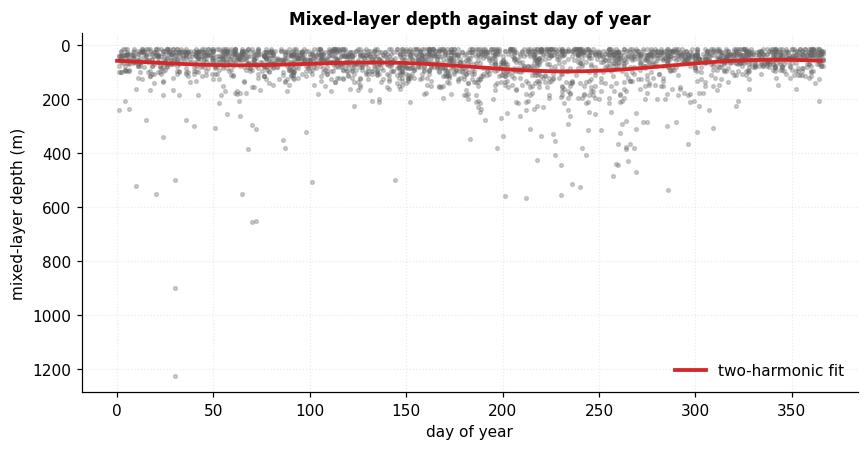

The two-harmonic fit explains 3 % of the variance in the mixed-layer depth. The first-harmonic amplitude is 13 m, and the fitted curve is deepest at about day 233 (around 21 August) and shallowest at about day 341. The remaining 97 % is profile-to-profile variability that a smooth seasonal curve cannot capture (eddies, storms, and the fact that floats sample different places).

In [57]:
tau = prof.TIME.dt.dayofyear.to_numpy() / 365.25
okm = np.isfinite(mld)
def design(t, k=2):
    cols = [np.ones_like(t)]
    for j in range(1, k + 1):
        cols += [np.cos(2 * np.pi * j * t), np.sin(2 * np.pi * j * t)]
    return np.column_stack(cols)

coef, *_ = np.linalg.lstsq(design(tau[okm]), mld[okm], rcond=None)
fit_all = design(np.linspace(0, 1, 366)) @ coef
mld_r2 = 1 - np.sum((mld[okm] - design(tau[okm]) @ coef) ** 2) / np.sum((mld[okm] - mld[okm].mean()) ** 2)
amp1 = float(np.hypot(coef[1], coef[2]))
peak_day = float(np.linspace(0, 1, 366)[np.argmax(fit_all)] * 365.25)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(tau[okm] * 365.25, mld[okm], s=6, alpha=0.3, color="0.4", rasterized=True)
ax.plot(np.linspace(0, 365.25, 366), fit_all, color="C3", lw=2.5, label="two-harmonic fit")
ax.set_xlabel("day of year"); ax.set_ylabel("mixed-layer depth (m)"); ax.invert_yaxis(); ax.legend()
ax.set_title("Mixed-layer depth against day of year")
plt.tight_layout(); save(fig, "fig13_mld_harmonic"); plt.show()

display(Markdown(
    f"The two-harmonic fit explains {100 * mld_r2:.0f} % of the variance in the mixed-layer depth. The first-harmonic amplitude is {amp1:.0f} m, and the fitted curve is deepest at about day {int(peak_day)} "
    f"(around {(pd.Timestamp('2001-01-01') + pd.Timedelta(days=int(peak_day) - 1)).strftime('%d %B')}) and shallowest at about day {int(np.linspace(0, 365.25, 366)[np.argmin(fit_all)])}. "
    f"The remaining {100 * (1 - mld_r2):.0f} % is profile-to-profile variability that a smooth seasonal curve cannot capture (eddies, storms, and the fact that floats sample different places)."))

---
<a id="s6"></a>
# 6. Limitations

A few features of the data and of the set-up are worth stating explicitly, because they limit how far the conclusions can be pushed (this is the equivalent of the "pathological cases" one usually checks in a modelling exercise). The cell below quantifies them.



In [59]:
# 1) N^2 should be >= 0 for a stable water column; how much of the data are not?
frac_neg_all = float((N2[np.isfinite(N2)] < 0).mean())
frac_neg_tab = float((y < 0).mean())

# 2) missing data as a function of depth
levels_show = [0, 10, 100, 500, 1000, 1500]
nan_by_depth = {f"{d} m": float(np.isnan(N2[:, np.abs(depth_all - d).argmin()]).mean()) for d in levels_show}

# 3) repeated time stamps (several profiles at the same instant) and float identity
n_dup_time = n_prof_all - pd.Series(time_all).nunique()

print(f"Share of finite N² values that are negative (all sampled levels): {100 * frac_neg_all:.2f} %")
print(f"Share of modelling-table rows with negative N²                    : {100 * frac_neg_tab:.2f} %")
print("Missing fraction of BRV2 by depth:", {k: round(v, 3) for k, v in nan_by_depth.items()})
print(f"Profiles sharing a time stamp with another profile: {n_dup_time:,} of {n_prof_all:,}")
print(f"Profile variables available for grouping: {[v for v in ds.variables if 'ID' in v.upper() or 'PLATFORM' in v.upper() or 'DBINDEX' in v.upper()]}")

Share of finite N² values that are negative (all sampled levels): 0.94 %
Share of modelling-table rows with negative N²                    : 2.25 %
Missing fraction of BRV2 by depth: {'0 m': 0.0, '10 m': 0.0, '100 m': 0.0, '500 m': 0.0, '1000 m': 0.0, '1500 m': 0.01}
Profiles sharing a time stamp with another profile: 2,862 of 128,910
Profile variables available for grouping: ['DBINDEX']


The points below summarise how these findings affect the interpretation:

* **Sampling.** Only a random subsample of the profiles (`N_PROF_SAMPLE`) and a thinned set of depth levels enter the models. The sample should be large enough for stable statistics, but the numbers will change somewhat with a different seed or sample size.
* **Negative $N^2$.** Some of the estimated $N^2$ values are negative (statically unstable; the share is printed above). This is partly real (convective overturning) and partly noise from taking gradients of measured profiles. I keep these values rather than clipping them, since they are part of the data, but they make the target heavy-tailed and probably limit the achievable R².
* **R² is dominated by the upper ocean.** $N^2$ is orders of magnitude larger in the thermocline than at depth, so squared-error metrics mostly reward getting the upper few hundred metres right (section 4e); a model that is good in the deep ocean gets little credit.
* **Collinearity.** The predictors are correlated (section 3b), so individual coefficients and importances should be read with care.
* **Region and time.** The results describe the region and years covered by this file (section 2a). The model should not be assumed to transfer to other ocean basins or to later years without re-checking (section 5a).

---
<a id="s7"></a>
# 7. Conclusion
The dataset, obtained from the Argo archive, spans 11 June 1999 to 6 January 2014 (about 14.5 years) and contains 128,910 profile records with 126,048 unique timestamps. In this study, BRV2 was used as the target variable, while temperature, salinity, depth, geographic location, and time of year were used as predictor variables to examine and model BRV2 variability.

**Predictability (Q1)**. On unseen profiles the best model was GradientBoosting (R²
 = 0.624, MAE = 0.159). The best linear model (Lasso) reached 0.238 and the best tree ensemble (GradientBoosting) 0.624. The bootstrap interval for the difference between the two families is +0.336 to +0.427, so the gap is distinguishable from zero once the profile-to-profile variability is accounted for.

**Predictors (Q2)**. For GradientBoosting, permutation importance ranks TEMP, PSAL highest.

**Where it fails (Q3)**. The largest absolute errors of GradientBoosting are in the 25 to 50 m layer; the largest relative errors are in the 0 to 25 m layer.

**Robustness (Q4)**. Moving from random profiles to a later time block changes the best R²
 from 0.624 to 0.652 (GradientBoosting).

**Gradients (Q5)**. With the vertical gradients supplied the best R²
 becomes 0.938 (RandomForest). Since 
 is, to good approximation, a linear function of those gradients, the limit on skill in the baseline reflects missing information about the local vertical structure more than any weakness of the algorithms.

Mixed layer. The annual harmonic explains 3 % of the variance of the profile-by-profile mixed-layer depth, with the deepest layer around day 233 of the year.

---
<a id="refs"></a>
# References

1.  Goh & Noh, (2013). Influence of the Coriolis force on the formation of a seasonal thermocline. *Ocean Dynamics*, **63**(9–10), 1083–1092. https://doi.org/10.1007/s10236-013-0634-6
2.  Pedregosa et al., (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, **12**, 2825–2830.
3.  Roberts et al., (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure.*Ecography*, **40**(8), 913–929.
4.  Roemmich et al., (2009). The Argo Program: Observing the global ocean with profiling floats. *Oceanography*, **22**(2), 34–43.
6.  Yamaguchi et al., (2019). Diagnosing the development of seasonal stratification using the potential energy anomaly in the North Pacific. *Climate Dynamics*, **53**(7–8), 4667–4681. https://doi.org/10.1007/s00382-019-04822-y
